# 01_EDA — Profiling of the 2026 Exports

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
T = {q: pd.read_csv(f'reports/tables/{q}.csv') for q in
     ['Q1', 'Q2_global', 'Q2_by_export', 'Q2_by_product', 'Q3', 'Q4_product', 'Q5_across_exports',
      'Q5_within_export', 'Q6', 'Q6b', 'Q7', 'Q8', 'Q9']}
g = T['Q2_global'].iloc[0]
print(f"Rows: {int(g['n_rows']):,} | with narrative: {int(g['n_with_narrative']):,} ({g['pct_with_narrative']}%)")

Rows: 4,851,531 | with narrative: 121,394 (2.5%)


## 1. Volume per Export

In [4]:
print(T['Q1'].merge(T['Q2_by_export'][['source_export_id', 'n_with_narrative', 'pct_with_narrative']],
                     on='source_export_id').to_string(index=False))

 source_export_id  n_rows min_date_received max_date_received  n_with_narrative  pct_with_narrative
               15 1038383        2026-01-01        2026-02-28             34351                3.31
               16  614945        2026-03-01        2026-03-31             21640                3.52
               17  618293        2026-04-01        2026-04-30             21052                3.40
               18  619940        2026-05-01        2026-05-31             17528                2.83
               19  620794        2026-06-01        2026-06-30             16820                2.71
               20  672036        2026-07-01        2026-07-31             10002                1.49
               21  667140        2026-08-01        2026-08-31                 1                0.00


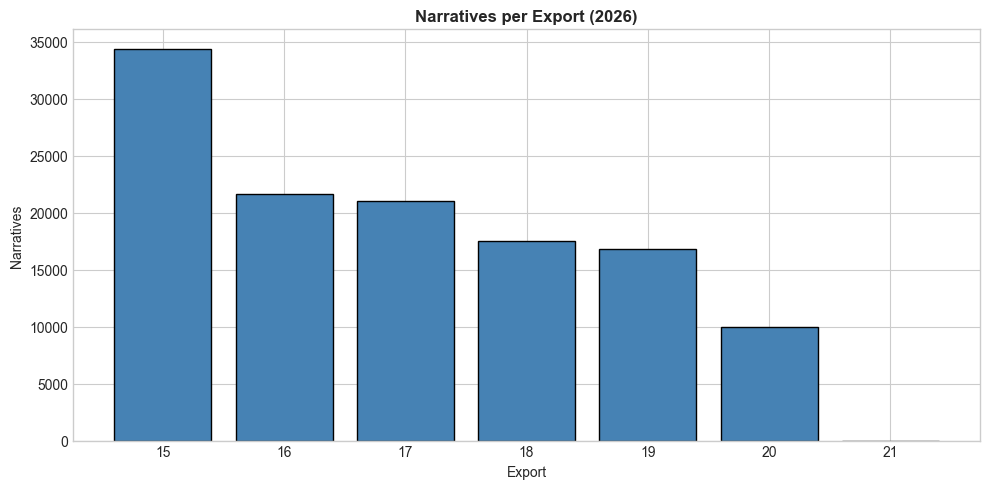

✓ Saved: 01_narratives_per_export.png


In [5]:
d = T['Q2_by_export']
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(d['source_export_id'].astype(str), d['n_with_narrative'], color='steelblue', edgecolor='black')
ax.set_title('Narratives per Export (2026)', fontsize=12, fontweight='bold')
ax.set_xlabel('Export'); ax.set_ylabel('Narratives')
plt.tight_layout()
plt.savefig('output/01_narratives_per_export.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 01_narratives_per_export.png')

## 2. Narrative Rate by Product

                                                product  n_rows  n_with_narrative  pct_with_narrative
    Credit reporting or other personal consumer reports 4405605              4945                0.11
                                        Debt collection  220785             40205               18.21
                                           Student loan   14228              4055               28.50
                                            Credit card   64866             20435               31.50
                                               Mortgage   23066              7772               33.69
Payday loan, title loan, personal loan, or advance loan   12597              4356               34.58
                                  Vehicle loan or lease   17022              5921               34.78
                            Checking or savings account   60354             21335               35.35
                                           Prepaid card    4102              1462 

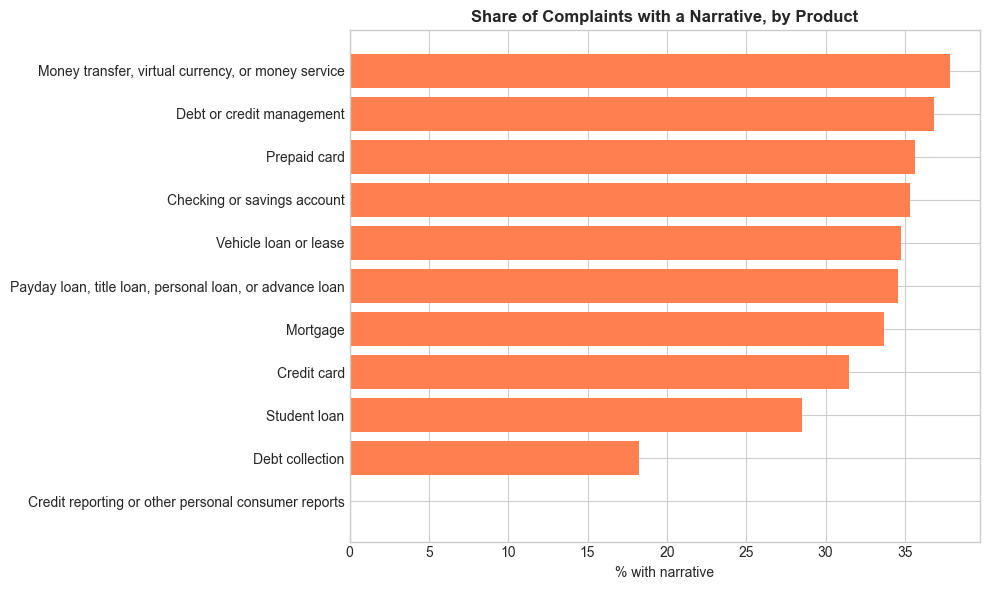

✓ Saved: 01_narrative_rate_by_product.png


In [6]:
d = T['Q2_by_product'].sort_values('pct_with_narrative')
print(d.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(d['product'], d['pct_with_narrative'], color='coral')
ax.set_title('Share of Complaints with a Narrative, by Product', fontsize=12, fontweight='bold')
ax.set_xlabel('% with narrative')
plt.tight_layout()
plt.savefig('output/01_narrative_rate_by_product.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 01_narrative_rate_by_product.png')

## 3. Taxonomy Stability (Product × Month)

received_month                                           2026-01  2026-02  2026-03  2026-04  2026-05  2026-06  2026-07  2026-08
product                                                                                                                        
Checking or savings account                               3792.0   1979.0   3450.0   3775.0   3044.0   3270.0   2025.0      0.0
Credit card                                               3788.0   1983.0   3362.0   3605.0   3035.0   2840.0   1822.0      0.0
Credit reporting or other personal consumer reports        862.0    513.0    816.0    793.0    746.0    751.0    463.0      1.0
Debt collection                                           7375.0   4377.0   8263.0   6642.0   5723.0   5098.0   2727.0      0.0
Debt or credit management                                  212.0    109.0    207.0    186.0    150.0    144.0     93.0      0.0
Money transfer, virtual currency, or money service        1767.0    982.0   1664.0   1843.0   1430.0   1

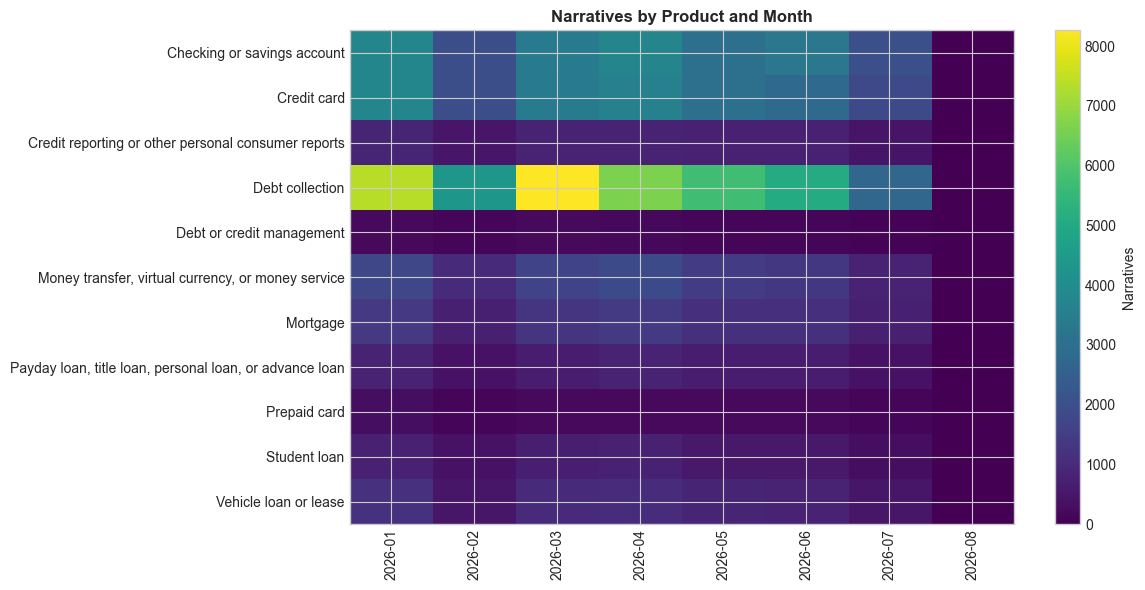

✓ Saved: 01_product_month_heatmap.png


In [7]:
pivot = T['Q3'].pivot_table(index='product', columns='received_month', values='n_narratives', fill_value=0)
print(pivot.to_string())
fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=90)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
fig.colorbar(im, ax=ax, label='Narratives')
ax.set_title('Narratives by Product and Month', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('output/01_product_month_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 01_product_month_heatmap.png')

## 4. Duplicates

In [8]:
print(f"Complaint ids in several exports: {int(T['Q5_across_exports'].iloc[0, 0]):,}")
print(f"Duplicated ids within an export: {int(T['Q5_within_export']['n_duplicated_ids'].sum()):,}")
print(f"Identical narratives: {int(T['Q6']['n_texts_duplicated'].iloc[0]):,} texts on {int(T['Q6']['n_rows_involved'].iloc[0]):,} rows")
print(f"  of which with different products: {int(T['Q6b']['n_texts_multi_product'].iloc[0]):,} texts on {int(T['Q6b']['n_rows_involved'].iloc[0]):,} rows")

Complaint ids in several exports: 0
Duplicated ids within an export: 0
Identical narratives: 2,014 texts on 13,777 rows
  of which with different products: 43 texts on 245 rows


## 5. Narrative Length & Masks

In [9]:
print('Words per narrative:'); print(T['Q7'].to_string(index=False))
print('\nMasks (XXXX):'); print(T['Q8'].to_string(index=False))

Words per narrative:
 min   p5  p25  median   p75   p95  max
   5 32.0 89.0   171.0 286.0 579.0 5347

Masks (XXXX):
 pct_narratives_with_mask  avg_masks_per_narrative
                    79.19                    10.59


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

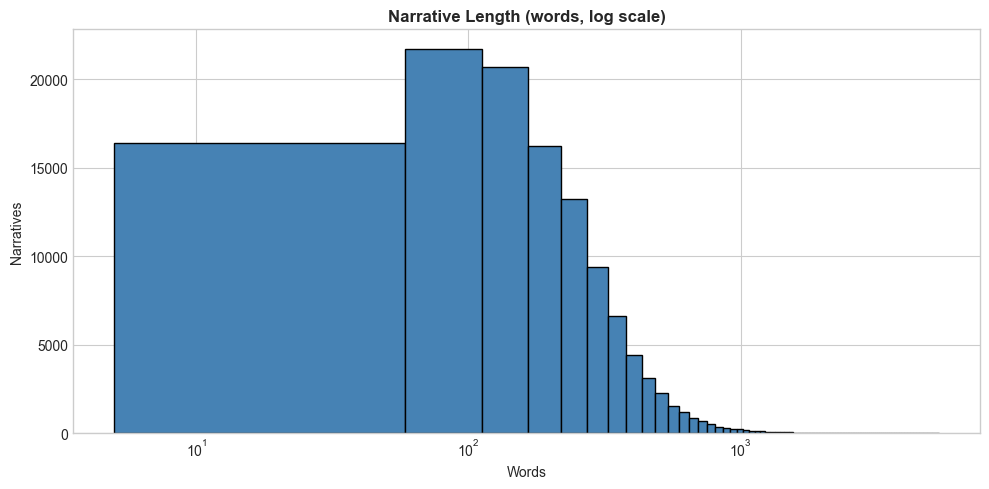

✓ Saved: 01_narrative_length_hist.png


In [10]:
import duckdb
narr = json.load(open('data/interim/columns.json', encoding='utf-8'))['keys']['narrative']
words = duckdb.sql(f"""SELECT len(string_split(trim(regexp_replace("{narr}", '\\s+', ' ', 'g')), ' ')) AS n
                      FROM read_parquet('data/interim/complaints_with_narrative.parquet')""").df()['n']
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(words, bins=100, color='steelblue', edgecolor='black')
ax.set_xscale('log')
ax.set_title('Narrative Length (words, log scale)', fontsize=12, fontweight='bold')
ax.set_xlabel('Words'); ax.set_ylabel('Narratives')
plt.tight_layout()
plt.savefig('output/01_narrative_length_hist.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 01_narrative_length_hist.png')

## 6. Excluded Product & Frozen Mapping

In [11]:
import yaml
print(T['Q9'].to_string(index=False))
mapping = yaml.safe_load(open('config/label_mapping.yaml', encoding='utf-8'))
print(f"\nMapping status: {mapping['status']} (frozen on {mapping['frozen_on']})")
for p, s in mapping['product_to_service'].items():
    print(f'  {p:<60} -> {s}')

                                            product  n_narratives  pct_of_narratives
Credit reporting or other personal consumer reports          4945               4.07

Mapping status: frozen (frozen on 2026-10-05)
  Checking or savings account                                  -> Comptes & Dépôts
  Credit card                                                  -> Monétique
  Prepaid card                                                 -> Monétique
  Money transfer, virtual currency, or money service           -> Transferts & Paiements
  Vehicle loan or lease                                        -> Crédits aux particuliers
  Payday loan, title loan, personal loan, or advance loan      -> Crédits aux particuliers
  Student loan                                                 -> Crédits aux particuliers
  Mortgage                                                     -> Crédit immobilier
  Debt collection                                              -> Recouvrement
  Debt or credit manage